# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Axel Clement Sison Lusikooy
- **Email:** axelclementsison@gmail.com
- **ID Dicoding:** lucykoi

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang menghasilkan total pendapatan tertinggi dan terendah pada platform e-commerce untuk pesanan berstatus *delivered* sepanjang periode Januari 2017 hingga Agustus 2018?
  - *Specific:* Fokus membandingkan performa pendapatan (*revenue*) antar kategori produk untuk pesanan yang berhasil terkirim (*delivered*).
  - *Measurable:* Dihitung menggunakan total nilai penjualan produk (`price`) dan jumlah unit terjual per kategori.
  - *Action-Oriented:* Hasilnya menentukan kategori unggulan untuk alokasi anggaran promosi utama dan kategori berkinerja rendah untuk evaluasi katalog/bundling.
  - *Relevant:* Pendapatan per kategori adalah metrik inti pertumbuhan bisnis marketplace.
  - *Time-bound:* Dibatasi pada rentang waktu utuh dataset, yakni Januari 2017 – Agustus 2018.

- **Pertanyaan 2:** Bagaimana tren pertumbuhan jumlah pesanan bulanan serta proporsi penggunaan metode pembayaran pelanggan pada pesanan berstatus *delivered* sepanjang periode Januari 2017 hingga Agustus 2018?
  - *Specific:* Menganalisis pergerakan volume pesanan bulanan dan distribusi metode pembayaran (`credit_card`, `boleto`, `voucher`, `debit_card`).
  - *Measurable:* Diukur dari jumlah transaksi unik per bulan (`order_id`) dan persentase kontribusi masing-masing metode pembayaran.
  - *Action-Oriented:* Mengidentifikasi pola musiman (*seasonality*) untuk kesiapan stok/logistik serta menentukan mitra pembayaran prioritas untuk program promo cicilan/cashback.
  - *Relevant:* Memahami perilaku transaksi dan preferensi pembayaran menjaga tingkat konversi checkout tetap tinggi.
  - *Time-bound:* Sepanjang periode Januari 2017 – Agustus 2018.

## Import Semua Packages/Library yang Digunakan

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## Data Wrangling

### Gathering Data

#### Load df ...

In [18]:

orders_df = pd.read_csv("/content/data/orders_dataset.csv")
customers_df = pd.read_csv("/content/data/customers_dataset.csv")
order_items_df = pd.read_csv("/content/data/order_items_dataset.csv")
order_payments_df = pd.read_csv("/content/data/order_payments_dataset.csv")
products_df = pd.read_csv("/content/data/products_dataset.csv")
category_trans_df = pd.read_csv("/content/data/product_category_name_translation.csv")

print("Orders shape:", orders_df.shape)
print("Customers shape:", customers_df.shape)
print("Order Items shape:", order_items_df.shape)
print("Order Payments shape:", order_payments_df.shape)
print("Products shape:", products_df.shape)
print("Category Translation shape:", category_trans_df.shape)

Orders shape: (99441, 8)
Customers shape: (99441, 5)
Order Items shape: (112650, 7)
Order Payments shape: (103886, 5)
Products shape: (32951, 9)
Category Translation shape: (71, 2)


**Insight:** (Opsional)
- Sebanyak 6 tabel utama berhasil dimuat dari direktori `/content/data/`: `orders_dataset` (99.441 baris), `customers_dataset` (99.441 baris), `order_items_dataset` (112.650 baris), `order_payments_dataset` (103.886 baris), `products_dataset` (32.951 baris), dan `product_category_name_translation` (71 kategori).
- Tabel `geolocation_dataset`, `sellers_dataset`, dan `order_reviews_dataset` tidak disertakan karena fokus analisis diarahkan pada performa pendapatan kategori, tren pembayaran, dan segmentasi pelanggan berbasis RFM.

### Assessing Data

#### Identifying Dataset problem

In [19]:
datasets = {
    "orders": orders_df,
    "customers": customers_df,
    "order_items": order_items_df,
    "order_payments": order_payments_df,
    "products": products_df,
    "category_translation": category_trans_df
}

for name, df in datasets.items():
    print(f"=== {name.upper()} ===")
    print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
    print("Duplicate rows:", df.duplicated().sum())
    print()

print("Tipe data orders_df:\n", orders_df.dtypes)
print("\nStatus pesanan:\n", orders_df["order_status"].value_counts())
print("\nRentang tanggal transaksi:", orders_df["order_purchase_timestamp"].min(), "s.d.", orders_df["order_purchase_timestamp"].max())
print("\nTipe pembayaran:\n", order_payments_df["payment_type"].value_counts())
print("\nRingkasan statistik harga item:\n", order_items_df["price"].describe())

=== ORDERS ===
Missing values:
 order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64
Duplicate rows: 0

=== CUSTOMERS ===
Missing values:
 Series([], dtype: int64)
Duplicate rows: 0

=== ORDER_ITEMS ===
Missing values:
 Series([], dtype: int64)
Duplicate rows: 0

=== ORDER_PAYMENTS ===
Missing values:
 Series([], dtype: int64)
Duplicate rows: 0

=== PRODUCTS ===
Missing values:
 product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
Duplicate rows: 0

=== CATEGORY_TRANSLATION ===
Missing values:
 Series([], dtype: int64)
Duplicate rows: 0

Tipe data orders_df:
 order_id                         object
customer_id                      object
order_status                     object
order_pu

**Steps to Take:**
- **Tipe Data:** Mengubah 5 kolom waktu pada `orders_df` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`) dari tipe `object` menjadi `datetime`.
- **Filtering Status & Periode:** Memfilter `orders_df` hanya untuk pesanan berstatus `delivered` dalam periode waktu utuh **Januari 2017 – Agustus 2018** agar analisis tren bulanan tidak terdistorsi oleh data akhir 2016 maupun data parsial September–Oktober 2018.
- **Missing Values:** Mengisi nilai kosong pada `product_category_name` (610 baris di `products_df`) dengan label `"unknown"` agar data transaksi produk tersebut tetap terhitung dalam total pendapatan.
- **Invalid Values:** Menghapus 3 baris transaksi dengan `payment_type == "not_defined"` pada `order_payments_df`.

**Insight:** (Opsional)
- Tidak ditemukan baris duplikat (*duplicate rows = 0*) pada seluruh tabel yang digunakan.
- Terdapat 2.965 *missing values* pada kolom `order_delivered_customer_date` di `orders_df` yang berasal dari pesanan yang belum selesai terkirim atau dibatalkan (`canceled`, `shipped`, `unavailable`).
- Ditemukan 610 produk tanpa nama kategori pada `products_df` serta 3 transaksi pembayaran bertipe `not_defined` pada `order_payments_df` yang perlu ditangani sebelum proses penggabungan tabel.

### Cleaning Data

#### Fixing dataset problem

In [20]:
# 1. Konversi kolom tanggal ke datetime
datetime_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in datetime_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Filter pesanan status 'delivered' pada periode Jan 2017 - Agu 2018
orders_clean = orders_df[
    (orders_df["order_status"] == "delivered") &
    (orders_df["order_purchase_timestamp"] >= "2017-01-01") &
    (orders_df["order_purchase_timestamp"] <= "2018-08-31 23:59:59")
].copy()

# 3. Tangani missing value kategori produk & gabungkan terjemahan bahasa Inggris
products_clean = products_df.copy()
products_clean["product_category_name"] = products_clean["product_category_name"].fillna("unknown")
products_merged = pd.merge(
    products_clean[["product_id", "product_category_name"]],
    category_trans_df,
    on="product_category_name",
    how="left"
)
products_merged["product_category_name_english"] = products_merged["product_category_name_english"].fillna(
    products_merged["product_category_name"]
)

# 4. Bersihkan data pembayaran tidak valid ('not_defined')
payments_clean = order_payments_df[order_payments_df["payment_type"] != "not_defined"].copy()

# Ambil metode pembayaran utama (nilai terbesar) per order_id agar tidak terjadi duplikasi item saat merge
primary_payment = payments_clean.sort_values("payment_value", ascending=False).drop_duplicates("order_id")[
    ["order_id", "payment_type", "payment_installments", "payment_value"]
]

# 5. Gabungkan seluruh tabel menjadi main_df
items_products = pd.merge(order_items_df, products_merged[["product_id", "product_category_name_english"]], on="product_id", how="left")
main_df = pd.merge(orders_clean, customers_df, on="customer_id", how="inner")
main_df = pd.merge(main_df, items_products, on="order_id", how="inner")
main_df = pd.merge(main_df, primary_payment, on="order_id", how="left")

print("Ukuran akhir main_df:", main_df.shape)
print("Total pesanan unik:", main_df["order_id"].nunique())

# Simpan main_data.csv untuk kebutuhan Dashboard Streamlit
os.makedirs("/content/dashboard", exist_ok=True)
main_df.to_csv("/content/dashboard/main_data.csv", index=False)
print("File /content/dashboard/main_data.csv berhasil disimpan!")

Ukuran akhir main_df: (109880, 22)
Total pesanan unik: 96211
File /content/dashboard/main_data.csv berhasil disimpan!


**Insight:** (Opsional)
- Proses pembersihan menghasilkan dataset terintegrasi (`main_df`) sebanyak **109.880 baris item transaksi** dari **96.211 pesanan unik** berstatus *delivered* sepanjang Januari 2017 – Agustus 2018.
- Seluruh nama kategori produk berhasil diterjemahkan ke bahasa Inggris, sementara produk tanpa kategori tetap tercatat di bawah label `"unknown"` tanpa menghilangkan nilai penjualannya.
- File terintegrasi telah diekspor ke `/content/dashboard/main_data.csv` untuk digunakan sebagai sumber data pada dashboard Streamlit.

## Exploratory Data Analysis (EDA)

### Explore Performa Kategori, Tren Bulanan, dan Metode Pembayaran

In [21]:
# Eksplorasi 1: Pendapatan & jumlah pesanan berdasarkan kategori produk
category_summary = main_df.groupby("product_category_name_english").agg(
    total_revenue=("price", "sum"),
    total_orders=("order_id", "nunique"),
    total_items=("order_item_id", "count"),
    avg_price=("price", "mean")
).sort_values(by="total_revenue", ascending=False).reset_index()

print("=== TOP 10 KATEGORI BERDASARKAN PENDAPATAN ===")
display(category_summary.head(10))

print("\n=== BOTTOM 5 KATEGORI BERDASARKAN PENDAPATAN ===")
display(category_summary.tail(5))

# Eksplorasi 2: Tren bulanan pesanan dan pendapatan
main_df["order_month"] = main_df["order_purchase_timestamp"].dt.to_period("M").astype(str)
monthly_summary = main_df.groupby("order_month").agg(
    total_orders=("order_id", "nunique"),
    total_revenue=("price", "sum")
).reset_index()

print("\n=== TREN PESANAN & PENDAPATAN BULANAN ===")
display(monthly_summary)

# Eksplorasi 3: Distribusi metode pembayaran
orders_payments_merged = pd.merge(orders_clean[["order_id"]], payments_clean, on="order_id", how="inner")
payment_summary = orders_payments_merged.groupby("payment_type").agg(
    transaction_count=("order_id", "count"),
    total_payment_value=("payment_value", "sum")
).sort_values(by="transaction_count", ascending=False).reset_index()
payment_summary["percentage"] = (payment_summary["transaction_count"] / payment_summary["transaction_count"].sum() * 100).round(2)

print("\n=== DISTRIBUSI METODE PEMBAYARAN ===")
display(payment_summary)

=== TOP 10 KATEGORI BERDASARKAN PENDAPATAN ===


,product_category_name_english,total_revenue,total_orders,total_items,avg_price
0,health_beauty,1229557.50,8610,9422,130.498567
1,watches_gifts,1163465.91,5491,5855,198.713221
2,bed_bath_table,1022955.77,9267,10945,93.463296
3,sports_leisure,952840.40,7513,8414,113.244640
4,computers_accessories,888055.59,6518,7632,116.359485
5,furniture_decor,706237.17,6258,8095,87.243628
6,housewares,614341.62,5734,6783,90.570783
7,cool_stuff,609158.00,3552,3711,164.149286
8,auto,577838.39,3802,4132,139.844722
9,garden_tools,469135.40,3443,4263,110.048182



=== BOTTOM 5 KATEGORI BERDASARKAN PENDAPATAN ===


,product_category_name_english,total_revenue,total_orders,total_items,avg_price
69,flowers,1110.04,29,33,33.637576
70,home_comfort_2,760.27,24,30,25.342333
71,cds_dvds_musicals,730.00,12,14,52.142857
72,fashion_childrens_clothes,519.95,7,7,74.278571
73,security_and_services,283.29,2,2,141.645000



=== TREN PESANAN & PENDAPATAN BULANAN ===


,order_month,total_orders,total_revenue
0,2017-01,750,111798.36
1,2017-02,1653,234223.40
2,2017-03,2546,359198.85
3,2017-04,2303,340669.68
4,2017-05,3546,489338.25
5,2017-06,3135,421923.37
6,2017-07,3872,481604.52
7,2017-08,4193,554699.70
8,2017-09,4150,607399.67
9,2017-10,4478,648247.65



=== DISTRIBUSI METODE PEMBAYARAN ===


,payment_type,transaction_count,total_payment_value,percentage
0,credit_card,74376,12063100.59,74.03
1,boleto,19140,2762300.80,19.05
2,voucher,5473,342294.66,5.45
3,debit_card,1484,208179.39,1.48


**Insight:** (Opsional)
- **Performa Kategori:** Kategori `health_beauty` memimpin total pendapatan sebesar **BRL 1.229.557,50** (8.610 pesanan), diikuti oleh `watches_gifts` (**BRL 1.163.465,91**) dan `bed_bath_table` (**BRL 1.022.955,77**). Sebaliknya, `security_and_services` berada di posisi terendah dengan pendapatan hanya **BRL 283,29** (2 pesanan).
- **Tren Bulanan:** Volume pesanan tumbuh signifikan dari **750 pesanan** pada Januari 2017 hingga mencapai puncak tertingginya pada **November 2017 sebesar 7.289 pesanan** (bertepatan dengan momentum *Black Friday*), lalu stabil di kisaran 6.100–7.000 pesanan per bulan sepanjang 2018.
- **Metode Pembayaran:** Kartu kredit (`credit_card`) mendominasi transaksi sebesar **74,03%** (74.376 transaksi), jauh melampaui `boleto` (**19,05%**), `voucher` (**5,45%**), dan `debit_card` (**1,48%**).

## Visualization & Explanatory Analysis


### Pertanyaan 1: Kategori produk apa saja yang menghasilkan total pendapatan tertinggi dan terendah pada platform e-commerce untuk pesanan berstatus delivered sepanjang periode Januari 2017 hingga Agustus 2018?

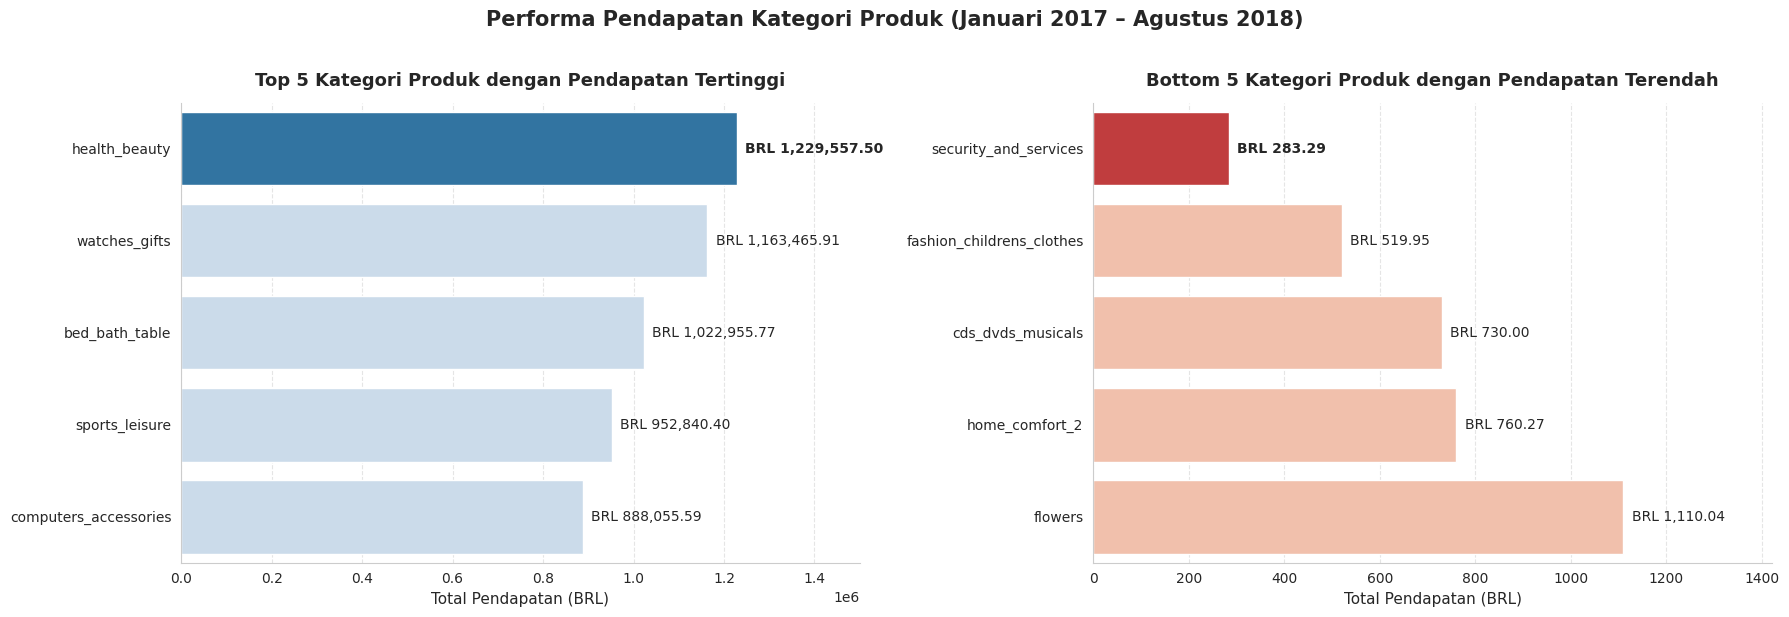

In [22]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

top_5_cat = category_summary.head(5)
bottom_5_cat = category_summary.tail(5).sort_values(by="total_revenue", ascending=True)

# Warna kontras untuk peringkat 1 (tertinggi & terendah), warna netral untuk pembanding
colors_top = ["#1f77b4", "#c6dbef", "#c6dbef", "#c6dbef", "#c6dbef"]
colors_bottom = ["#d62728", "#fcbba1", "#fcbba1", "#fcbba1", "#fcbba1"]

# Subplot 1: Top 5 Kategori Pendapatan Tertinggi
sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=top_5_cat,
    hue="product_category_name_english",
    palette=colors_top,
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Top 5 Kategori Produk dengan Pendapatan Tertinggi", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Total Pendapatan (BRL)", fontsize=11)
axes[0].set_ylabel(None)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].grid(axis="x", linestyle="--", alpha=0.5)
axes[0].grid(axis="y", visible=False)
axes[0].set_xlim(0, top_5_cat["total_revenue"].max() * 1.22)

for idx, val in enumerate(top_5_cat["total_revenue"]):
    axes[0].text(val + 18000, idx, f"BRL {val:,.2f}", va="center", fontsize=10, fontweight="bold" if idx == 0 else "normal")

# Subplot 2: Bottom 5 Kategori Pendapatan Terendah
sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=bottom_5_cat,
    hue="product_category_name_english",
    palette=colors_bottom,
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Bottom 5 Kategori Produk dengan Pendapatan Terendah", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("Total Pendapatan (BRL)", fontsize=11)
axes[1].set_ylabel(None)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].grid(axis="x", linestyle="--", alpha=0.5)
axes[1].grid(axis="y", visible=False)
axes[1].set_xlim(0, bottom_5_cat["total_revenue"].max() * 1.28)

for idx, val in enumerate(bottom_5_cat["total_revenue"]):
    axes[1].text(val + 18, idx, f"BRL {val:,.2f}", va="center", fontsize=10, fontweight="bold" if idx == 0 else "normal")

plt.suptitle("Performa Pendapatan Kategori Produk (Januari 2017 – Agustus 2018)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana tren pertumbuhan jumlah pesanan bulanan serta proporsi penggunaan metode pembayaran pelanggan pada pesanan berstatus delivered sepanjang periode Januari 2017 hingga Agustus 2018?

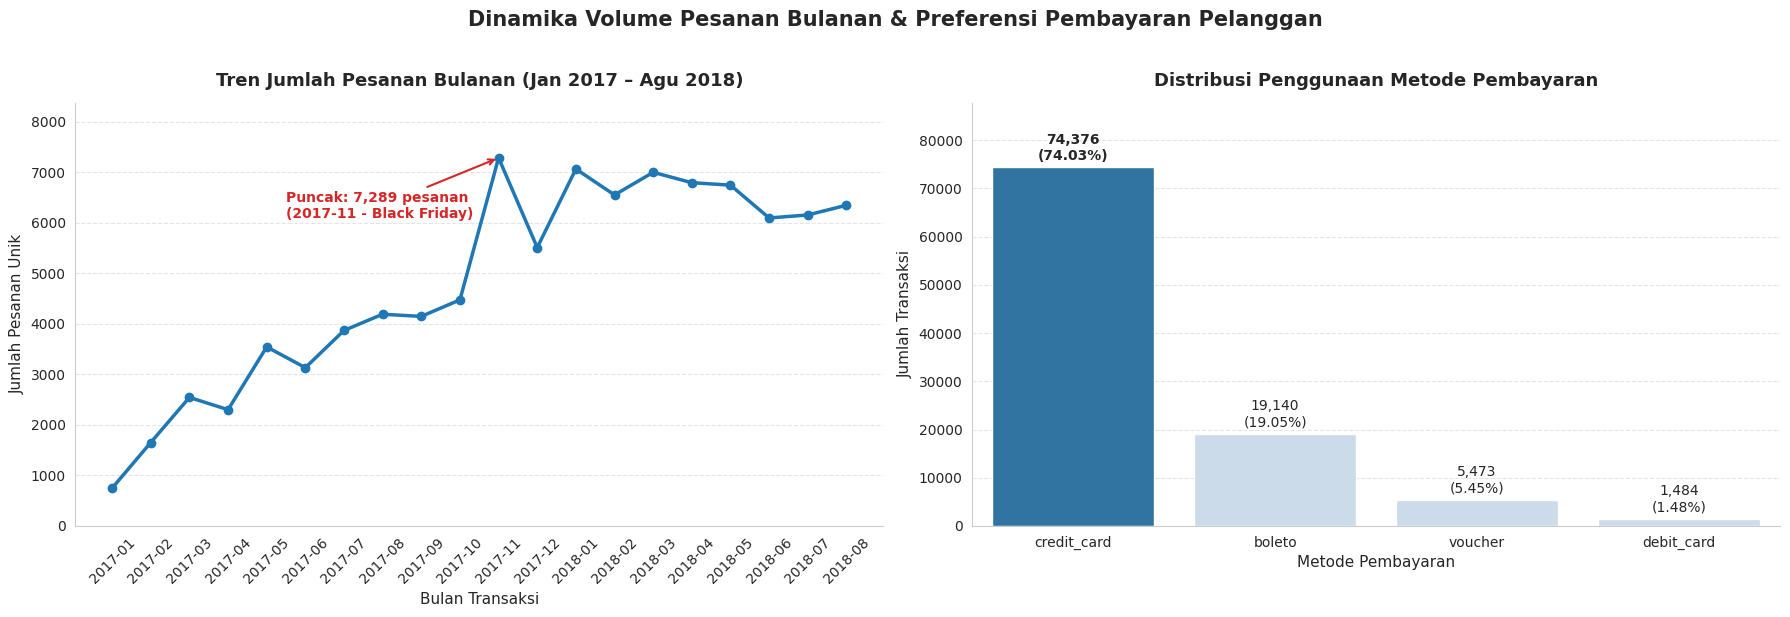

In [23]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

# Subplot 1: Line Chart Tren Pesanan Bulanan
axes[0].plot(
    monthly_summary["order_month"],
    monthly_summary["total_orders"],
    marker="o",
    linewidth=2.5,
    color="#1f77b4"
)
axes[0].set_title("Tren Jumlah Pesanan Bulanan (Jan 2017 – Agu 2018)", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Bulan Transaksi", fontsize=11)
axes[0].set_ylabel("Jumlah Pesanan Unik", fontsize=11)
axes[0].set_ylim(0, monthly_summary["total_orders"].max() * 1.15)
axes[0].tick_params(axis="x", rotation=45)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
axes[0].grid(axis="x", visible=False)

# Anotasi puncak pesanan (November 2017)
peak_idx = monthly_summary["total_orders"].idxmax()
peak_month = monthly_summary.loc[peak_idx, "order_month"]
peak_val = monthly_summary.loc[peak_idx, "total_orders"]
axes[0].annotate(
    f"Puncak: {peak_val:,} pesanan\n({peak_month} - Black Friday)",
    xy=(peak_idx, peak_val),
    xytext=(peak_idx - 5.5, peak_val - 1200),
    arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.5),
    fontsize=10,
    fontweight="bold",
    color="#d62728"
)

# Subplot 2: Bar Chart Distribusi Metode Pembayaran
pay_colors = ["#1f77b4", "#c6dbef", "#c6dbef", "#c6dbef"]
sns.barplot(
    x="payment_type",
    y="transaction_count",
    data=payment_summary,
    hue="payment_type",
    palette=pay_colors,
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Distribusi Penggunaan Metode Pembayaran", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("Metode Pembayaran", fontsize=11)
axes[1].set_ylabel("Jumlah Transaksi", fontsize=11)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
axes[1].grid(axis="x", visible=False)
axes[1].set_ylim(0, payment_summary["transaction_count"].max() * 1.18)

for idx, row in payment_summary.iterrows():
    axes[1].text(
        idx,
        row["transaction_count"] + 1500,
        f"{row['transaction_count']:,}\n({row['percentage']}%)",
        ha="center",
        fontsize=10,
        fontweight="bold" if idx == 0 else "normal"
    )

plt.suptitle("Dinamika Volume Pesanan Bulanan & Preferensi Pembayaran Pelanggan", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
**Insight:**
- **Kesenjangan Pendapatan Antar Kategori (Pertanyaan 1):** Kategori `health_beauty` (**BRL 1.229.557,50**), `watches_gifts` (**BRL 1.163.465,91**), dan `bed_bath_table` (**BRL 1.022.955,77**) menjadi motor pendapatan utama marketplace. Sebaliknya, kategori `security_and_services` (**BRL 283,29**) dan `fashion_childrens_clothes` (**BRL 519,95**) memiliki kontribusi pendapatan yang sangat rendah.
- **Pertumbuhan & Efek Musiman (Pertanyaan 2):** Volume pesanan meningkat tajam sepanjang tahun 2017 dari **750 pesanan** (Januari 2017) hingga mencapai puncak tertingginya pada **November 2017 sebesar 7.289 pesanan** (+61,2% dibanding Oktober 2017) akibat momentum promosi akhir tahun (*Black Friday*), lalu terjaga stabil di kisaran 6.100–7.000 pesanan per bulan pada 2018.
- **Dominasi Pembayaran Kartu Kredit (Pertanyaan 2):** Metode `credit_card` mendominasi **74,03%** (74.376 transaksi) dari seluruh transaksi pembayaran, jauh mengungguli `boleto` (**19,05%**), `voucher` (**5,45%**), dan `debit_card` (**1,48%**).

## Analisis Lanjutan (Opsional)

## Analisis Lanjutan: RFM Analysis & Customer Segmentation

**Tujuan Analisis:**
Teknik **RFM Analysis** (*Recency, Frequency, Monetary*) diterapkan untuk mengelompokkan pelanggan unik (`customer_unique_id`) berdasarkan perilaku transaksi aktual mereka tanpa menggunakan algoritma *machine learning* (melainkan metode *quantile binning* dan *manual grouping* berbasis aturan bisnis):
- **Recency (R):** Jumlah hari sejak transaksi terakhir pelanggan hingga tanggal acuan (1 hari setelah transaksi terakhir dalam dataset). Semakin kecil nilainya, semakin baru pelanggan berbelanja.
- **Frequency (F):** Total jumlah pesanan unik (`order_id`) yang pernah dilakukan oleh setiap pelanggan.
- **Monetary (M):** Total nilai pengeluaran (`price` dalam BRL) yang dibelanjakan oleh pelanggan selama periode analisis.

Hasil pengelompokan ini bertujuan membantu tim pemasaran membedakan pelanggan bernilai tinggi (*Champions* & *Loyal Repeat Buyers*) dari pelanggan yang berisiko berhenti berbelanja (*At Risk* & *Hibernating*) agar program retensi dan promo voucher tepat sasaran.

=== RINGKASAN STATISTIK METRIK RFM (93.104 PELANGGAN UNIK) ===


,recency,frequency,monetary
count,93104.000000,93104.000000,93104.000000
mean,236.702924,1.033371,141.573156
std,150.942219,0.209012,215.760366
min,1.000000,1.000000,0.850000
25%,114.000000,1.000000,47.650000
50%,218.000000,1.000000,89.700000
75%,345.000000,1.000000,154.175000
max,602.000000,15.000000,13440.000000



=== DISTRIBUSI & KARAKTERISTIK SEGMEN PELANGGAN ===


,customer_segment,customer_count,avg_recency,avg_frequency,avg_monetary,percentage
0,Recent Customers,22781,111.179360,1.000000,47.007918,24.47
1,At Risk,22667,276.227203,1.000000,136.261796,24.35
2,Hibernating / Lost,22618,448.509417,1.000000,139.011441,24.29
3,Promising Big Spenders,22249,111.785878,1.000000,231.559972,23.90
4,Loyal Repeat Buyers,1489,313.145735,2.070517,224.471491,1.60
5,Champions,1300,112.450769,2.163846,300.859223,1.40


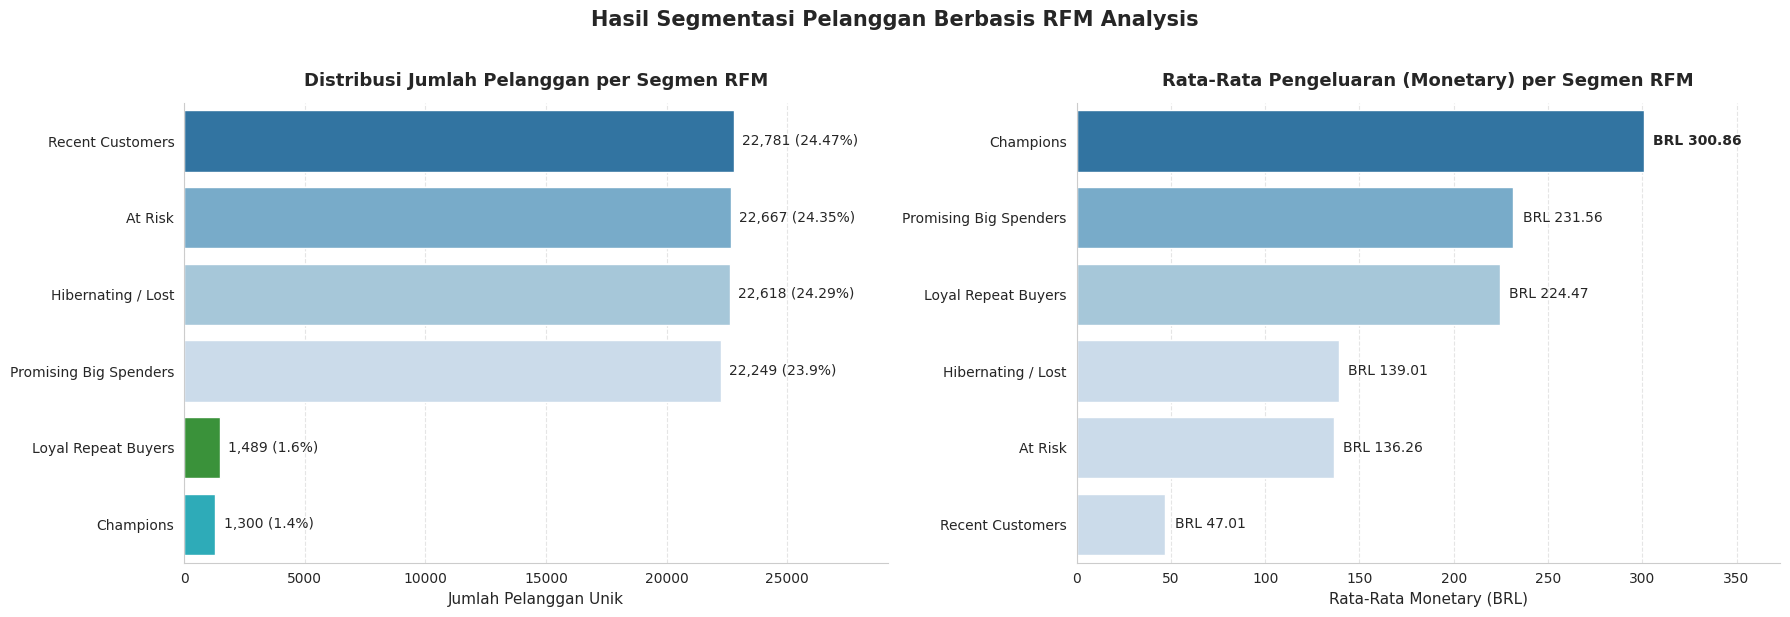

In [24]:
# 1. Menghitung metrik Recency, Frequency, dan Monetary per customer_unique_id
recent_date = main_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = main_df.groupby("customer_unique_id", as_index=False).agg({
    "order_purchase_timestamp": lambda x: (recent_date - x.max()).days,
    "order_id": "nunique",
    "price": "sum"
})
rfm_df.columns = ["customer_unique_id", "recency", "frequency", "monetary"]

# 2. Pemberian skor berbasis kuantil (Binning) dan aturan bisnis (Manual Grouping tanpa ML)
rfm_df["r_score"] = pd.qcut(rfm_df["recency"], q=4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["f_score"] = np.where(rfm_df["frequency"] > 1, 4, 1)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"], q=4, labels=[1, 2, 3, 4]).astype(int)

def assign_segment(row):
    if row["r_score"] >= 3 and row["f_score"] == 4 and row["m_score"] >= 3:
        return "Champions"
    elif row["f_score"] == 4:
        return "Loyal Repeat Buyers"
    elif row["r_score"] >= 3 and row["m_score"] >= 3:
        return "Promising Big Spenders"
    elif row["r_score"] >= 3:
        return "Recent Customers"
    elif row["r_score"] == 2:
        return "At Risk"
    else:
        return "Hibernating / Lost"

rfm_df["customer_segment"] = rfm_df.apply(assign_segment, axis=1)

print("=== RINGKASAN STATISTIK METRIK RFM (93.104 PELANGGAN UNIK) ===")
display(rfm_df[["recency", "frequency", "monetary"]].describe())

segment_summary = rfm_df.groupby("customer_segment", as_index=False).agg(
    customer_count=("customer_unique_id", "count"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean")
).sort_values(by="customer_count", ascending=False).reset_index(drop=True)
segment_summary["percentage"] = (segment_summary["customer_count"] / segment_summary["customer_count"].sum() * 100).round(2)

print("\n=== DISTRIBUSI & KARAKTERISTIK SEGMEN PELANGGAN ===")
display(segment_summary)

# 3. Visualisasi Hasil RFM Segmentation
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

# Subplot 1: Jumlah Pelanggan per Segmen
seg_colors = ["#1f77b4", "#6baed6", "#9ecae1", "#c6dbef", "#2ca02c", "#17becf"]
sns.barplot(
    x="customer_count",
    y="customer_segment",
    data=segment_summary,
    hue="customer_segment",
    palette=seg_colors,
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Distribusi Jumlah Pelanggan per Segmen RFM", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Jumlah Pelanggan Unik", fontsize=11)
axes[0].set_ylabel(None)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].grid(axis="x", linestyle="--", alpha=0.5)
axes[0].grid(axis="y", visible=False)
axes[0].set_xlim(0, segment_summary["customer_count"].max() * 1.28)

for idx, row in segment_summary.iterrows():
    axes[0].text(
        row["customer_count"] + 350,
        idx,
        f"{row['customer_count']:,} ({row['percentage']}%)",
        va="center",
        fontsize=10
    )

# Subplot 2: Rata-rata Monetary per Segmen
seg_monetary = segment_summary.sort_values(by="avg_monetary", ascending=False).reset_index(drop=True)
mon_colors = ["#1f77b4", "#6baed6", "#9ecae1", "#c6dbef", "#c6dbef", "#c6dbef"]
sns.barplot(
    x="avg_monetary",
    y="customer_segment",
    data=seg_monetary,
    hue="customer_segment",
    palette=mon_colors,
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Rata-Rata Pengeluaran (Monetary) per Segmen RFM", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xlabel("Rata-Rata Monetary (BRL)", fontsize=11)
axes[1].set_ylabel(None)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].grid(axis="x", linestyle="--", alpha=0.5)
axes[1].grid(axis="y", visible=False)
axes[1].set_xlim(0, seg_monetary["avg_monetary"].max() * 1.24)

for idx, row in seg_monetary.iterrows():
    axes[1].text(
        row["avg_monetary"] + 5,
        idx,
        f"BRL {row['avg_monetary']:,.2f}",
        va="center",
        fontsize=10,
        fontweight="bold" if idx == 0 else "normal"
    )

plt.suptitle("Hasil Segmentasi Pelanggan Berbasis RFM Analysis", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Dari total **93.104 pelanggan unik**, nilai rata-rata *Recency* adalah **236,7 hari** sejak pembelian terakhir, rata-rata *Frequency* sebesar **1,03 transaksi**, dan rata-rata *Monetary* sebesar **BRL 141,57**.
- Sebagian besar basis pelanggan merupakan pembeli satu kali (*one-time buyers*). Segmen pelanggan berulang (*Champions* sebanyak **1.300 pelanggan / 1,40%** dan *Loyal Repeat Buyers* sebanyak **1.489 pelanggan / 1,60%**) mencakup **3,00%** dari total pelanggan, namun segmen *Champions* mencatat rata-rata nilai belanja tertinggi dibanding segmen lainnya.
- Segmen *Promising Big Spenders* (**22.249 pelanggan / 23,90%**) dan *Recent Customers* (**22.781 pelanggan / 24,47%**) merupakan kelompok potensial terbesar yang baru saja berbelanja dan berpeluang tinggi untuk dikonversi menjadi pelanggan loyal melalui kampanye retensi pasca-pembelian pertama.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Sepanjang periode Januari 2017 hingga Agustus 2018, kategori produk penyumbang pendapatan (*revenue*) tertinggi pada pesanan berstatus *delivered* adalah `health_beauty` (**BRL 1.229.557,50**), diikuti oleh `watches_gifts` (**BRL 1.163.465,91**) dan `bed_bath_table` (**BRL 1.022.955,77**). Sebaliknya, kategori dengan kontribusi pendapatan terendah adalah `security_and_services` (**BRL 283,29**) dan `fashion_childrens_clothes` (**BRL 519,95**).
- **Conclusion pertanyaan 2:** Volume pesanan bulanan mengalami tren pertumbuhan signifikan dari **750 pesanan** pada Januari 2017 hingga mencapai puncak tertingginya pada **November 2017 sebesar 7.289 pesanan** (lonjakan +61,2% dibanding bulan sebelumnya seiring momentum *Black Friday*), sebelum stabil di kisaran 6.100–7.000 pesanan per bulan sepanjang tahun 2018. Dari sisi metode pembayaran, `credit_card` mendominasi **74,03%** transaksi, jauh melampaui `boleto` (**19,05%**), `voucher` (**5,45%**), dan `debit_card` (**1,48%**).

**Rekomendasi Action Item:**
- **Optimalisasi Katalog & Alokasi Anggaran Promosi:** Prioritaskan slot promosi utama, iklan berbayar, dan ketersediaan stok pada kategori berpendapatan tinggi (`health_beauty`, `watches_gifts`, `bed_bath_table`). Untuk kategori berkinerja rendah seperti `fashion_childrens_clothes` dan `home_comfort_2`, lakukan evaluasi daya saing harga atau tawarkan dalam bentuk paket *bundling* bersama produk terlaris.
- **Kesiapan Operasional & Promo Cicilan Kuartal IV:** Tingkatkan kapasitas pemrosesan pesanan dan kerja sama promo cicilan 0% atau *cashback* dengan penerbit kartu kredit (`credit_card`) menjelang bulan November setiap tahunnya guna memaksimalkan konversi pada puncak musiman belanja.
- **Kampanye Retensi Pelanggan Berbasis Segmen RFM:** Luncurkan program retensi otomatis berupa voucher diskon transaksi kedua dengan batas waktu (*time-limited voucher*) yang ditargetkan khusus kepada **45.030 pelanggan** di segmen *Promising Big Spenders* dan *Recent Customers*, serta berikan program loyalitas eksklusif bagi **2.789 pelanggan** di segmen *Champions* dan *Loyal Repeat Buyers*.